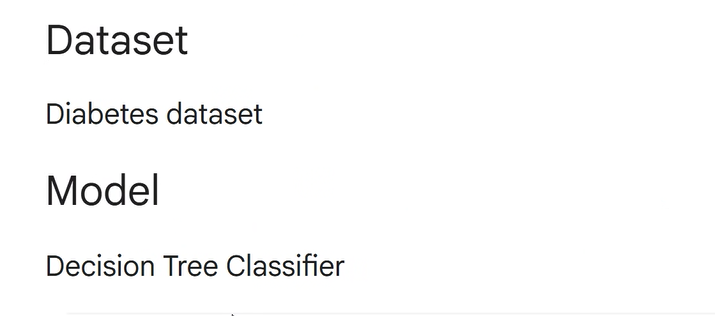

In [71]:
import pandas as pd

In [72]:
import os
import urllib.request

# Check if file exists; if not, download it
csv_url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
if not os.path.exists('diabetes.csv'):
    print("Downloading diabetes.csv...")
    urllib.request.urlretrieve(csv_url, 'diabetes.csv')

# Give column names
diabetes_columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

diabetes = pd.read_csv('diabetes.csv', names=diabetes_columns)
diabetes.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [73]:
diabetes.tail()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [74]:
print("rows",diabetes.shape[0])
print("columns",diabetes.shape[1])

rows 768
columns 9


In [75]:
diabetes.columns.tolist()


['Pregnancies',
 'Glucose',
 'BloodPressure',
 'SkinThickness',
 'Insulin',
 'BMI',
 'DiabetesPedigreeFunction',
 'Age',
 'Outcome']

In [76]:
#datatypes
diabetes.dtypes


,0
Pregnancies,int64
Glucose,int64
BloodPressure,int64
SkinThickness,int64
Insulin,int64
BMI,float64
DiabetesPedigreeFunction,float64
Age,int64
Outcome,int64


In [77]:
#info
diabetes.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [78]:
#describe
diabetes.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [79]:
#identify input and target
diabetes_input = diabetes.drop('Outcome',axis=1)
diabetes_target = diabetes['Outcome']

In [80]:
diabetes.duplicated().sum()

np.int64(0)

In [81]:
import numpy as np
invalid_zero_columns=[
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

diabetes[invalid_zero_columns] = diabetes[invalid_zero_columns].replace(0,np.nan)


In [82]:
diabetes.isnull().sum()

,0
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0


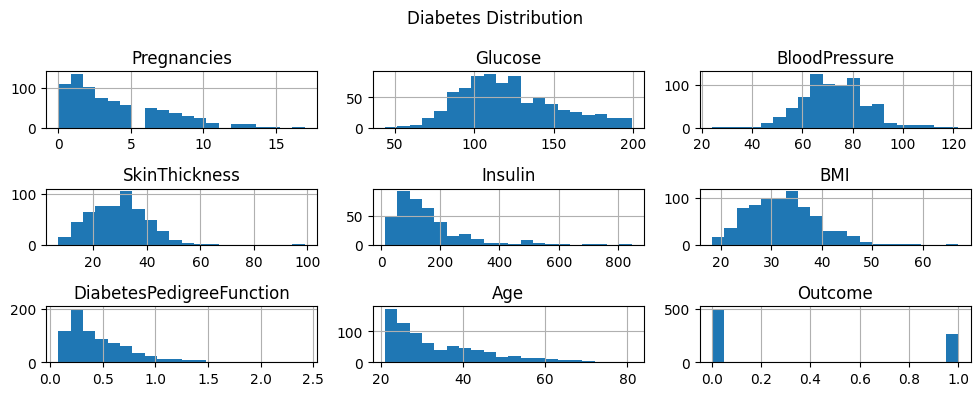

In [83]:
import matplotlib.pyplot as plt

diabetes.hist(bins=20,figsize=(10,4))
plt.suptitle("Diabetes Distribution")
plt.tight_layout()
plt.show()

In [84]:
diabetes.skew()

,0
Pregnancies,0.901674
Glucose,0.530989
BloodPressure,0.134153
SkinThickness,0.690619
Insulin,2.166464
BMI,0.593970
DiabetesPedigreeFunction,1.919911
Age,1.129597
Outcome,0.635017


In [85]:
for column in diabetes.columns:
  # Calculate skewness for the specific column
  skew_value = diabetes[column].skew()

  if -0.5 <= skew_value<= 0.5:
    print(f"{column}: Use Mean  ")
  else:
    print(f"{column}: Use Median ")

Pregnancies: Use Median 
Glucose: Use Median 
BloodPressure: Use Mean  
SkinThickness: Use Median 
Insulin: Use Median 
BMI: Use Median 
DiabetesPedigreeFunction: Use Median 
Age: Use Median 
Outcome: Use Median 


In [86]:
diabetes["Pregnancies"]=diabetes["Pregnancies"].fillna(diabetes["Pregnancies"].median())
diabetes['Glucose']=diabetes['Glucose'].fillna(diabetes['Glucose'].median())
diabetes['BloodPressure']=diabetes['BloodPressure'].fillna(diabetes['BloodPressure'].mean())
diabetes['SkinThickness']=diabetes['SkinThickness'].fillna(diabetes['SkinThickness'].median())
diabetes['Insulin']=diabetes['Insulin'].fillna(diabetes['Insulin'].median())
diabetes['BMI']=diabetes['BMI'].fillna(diabetes['BMI'].median())
diabetes['DiabetesPedigreeFunction']=diabetes['DiabetesPedigreeFunction'].fillna(diabetes['DiabetesPedigreeFunction'].median())
diabetes['Age']=diabetes['Age'].fillna(diabetes['Age'].median())
diabetes['Outcome']=diabetes['Outcome'].fillna(diabetes['Outcome'].median())

In [87]:
diabetes.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [88]:
diabetes['Outcome'].value_counts()

,count
Outcome,
0,500
1,268


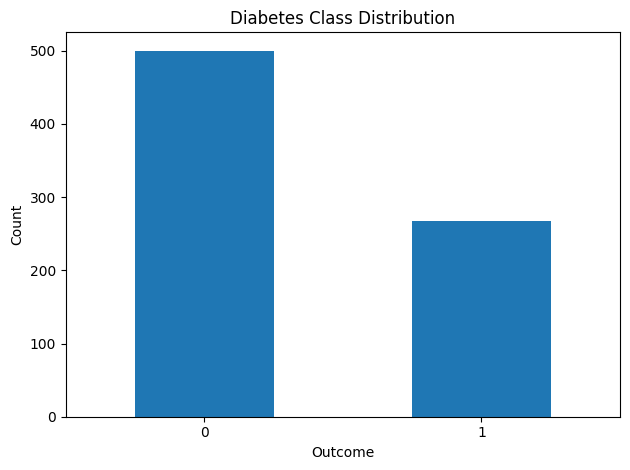

In [89]:
diabetes['Outcome'].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Diabetes Class Distribution")
plt.xlabel("Outcome")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [90]:
X_diabetes = diabetes.drop('Outcome',axis=1)
y_diabetes = diabetes['Outcome']
print("Input Shape :",X_diabetes.shape)
print("Target Shape :",y_diabetes.shape)

Input Shape : (768, 8)
Target Shape : (768,)


In [91]:
from sklearn.model_selection import train_test_split

X_train_diabetes,X_test_diabetes,y_train_diabetes,y_test_diabetes = train_test_split(X_diabetes,y_diabetes,train_size=.8,test_size=0.2,random_state=42)
print("Training rows",X_train_diabetes.shape[0])
print("Testing rows",X_test_diabetes.shape[0])

Training rows 614
Testing rows 154


In [92]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
decision_tree_model=DecisionTreeClassifier(max_depth=4,class_weight="balanced",random_state=42)

In [93]:
decision_tree_model.fit(X_train_diabetes,y_train_diabetes)
decision_tree_model_pred=decision_tree_model.predict(X_test_diabetes)


In [94]:
Accuracy = accuracy_score(y_test_diabetes,decision_tree_model_pred)

print(f"Accuracy:{Accuracy*100}%")

Accuracy:70.12987012987013%


accuracy , precision , recall , confusion matrix , f1score all are evaluation metrics for classification

In [95]:
print(classification_report(y_test_diabetes,decision_tree_model_pred))

              precision    recall  f1-score   support

           0       0.86      0.64      0.73        99
           1       0.56      0.82      0.66        55

    accuracy                           0.70       154
   macro avg       0.71      0.73      0.70       154
weighted avg       0.75      0.70      0.71       154



In [96]:
print(confusion_matrix(y_test_diabetes,decision_tree_model_pred))

[[63 36]
 [10 45]]


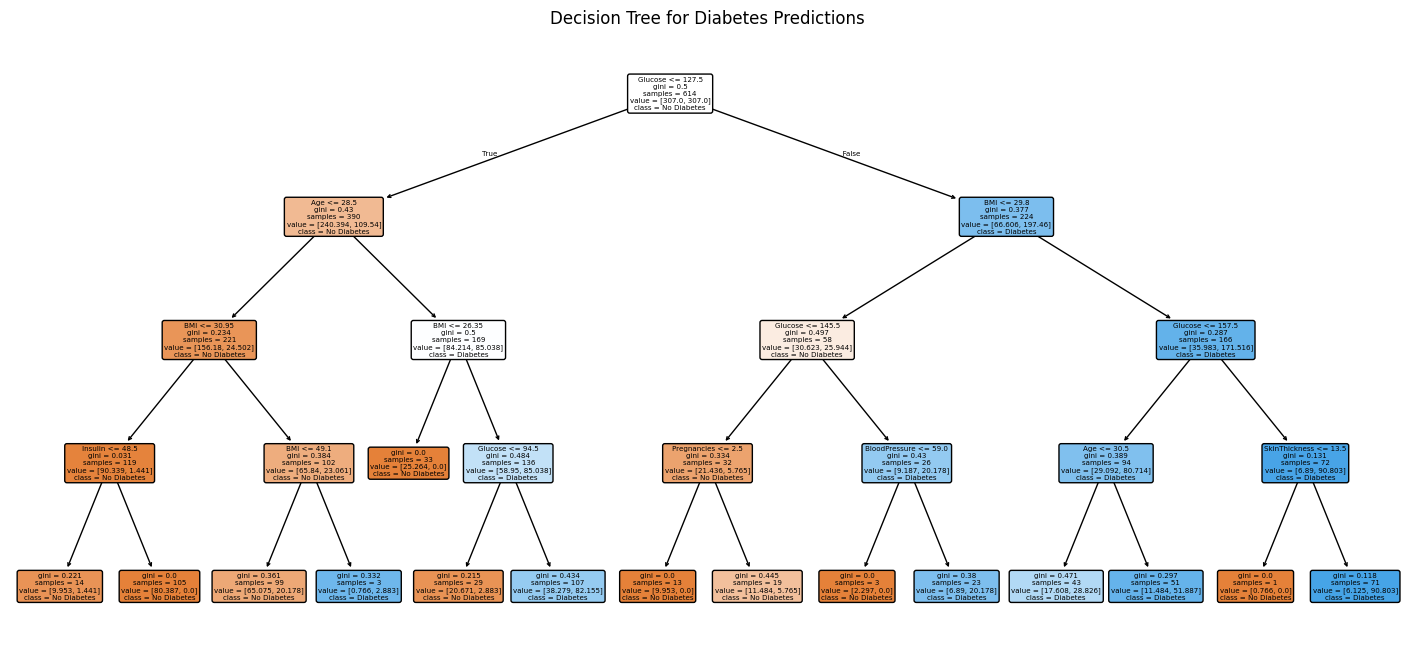

In [97]:
from sklearn.tree import plot_tree

plt.figure(figsize=(18,8))
plot_tree(decision_tree_model,feature_names=X_diabetes.columns,class_names=["No Diabetes","Diabetes"],filled=True,rounded=True)
plt.title("Decision Tree for Diabetes Predictions")
plt.show()

In [98]:
import pandas as pd

# Define new unknown patient data with values matching the feature names and ranges
unknown_diabetes = pd.DataFrame([
    {
        "Pregnancies": 2,
        "Glucose": 120.0,
        "BloodPressure": 70.0,
        "SkinThickness": 25.0,
        "Insulin": 110.0,
        "BMI": 30.0,
        "DiabetesPedigreeFunction": 0.450,
        "Age": 35
    }
])



In [99]:
# Make a prediction using the trained model
prediction = decision_tree_model.predict(unknown_diabetes)[0]
prediction_prob = decision_tree_model.predict_proba(unknown_diabetes)

print("Predicted Patient Data:",prediction)
print("Prediction Probability:",prediction_prob)
display(unknown_diabetes)



Predicted Patient Data: 1
Prediction Probability: [[0.31784403 0.68215597]]


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,2,120.0,70.0,25.0,110.0,30.0,0.45,35


In [100]:
# Output prediction result
if prediction == 1:
    print("Result: Diabetes")
else:
    print("Result: No Diabetes ")

Result: Diabetes


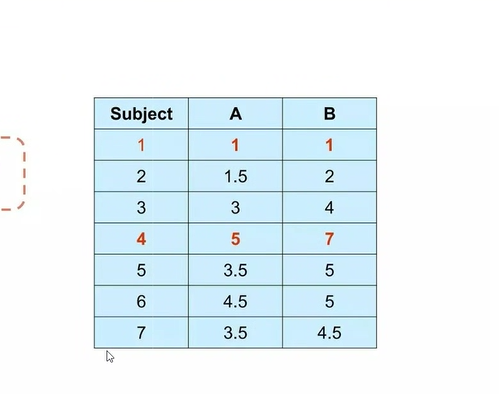